# Food-101 Image Classification: ResNet and Custom CNN Layers

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

content_path = './'   # Food-101 and the saved models are stored here
rng_seed = 90

## Part 1: Convolution, max-pooling, linear and batch-normalisation layers from scratch

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class Conv2d(nn.Module):
    def __init__(self,
                 in_channels,
                 out_channels,
                 kernel_size,
                 stride=1,
                 padding=0,
                 bias=True):

        super(Conv2d, self).__init__()
        """
        An implementation of a convolutional layer.

        The input consists of N data points, each with C channels, height H and
        width W. We convolve each input with F different filters, where each filter
        spans all C channels and has height H' and width W'.

        Parameters:
        - kernel_size: Union[int, (int, int)], Size of the convolving kernel. (H', W') if tuple.
        - stride: Union[int, (int, int)], Number of pixels between adjacent receptive fields in the
            horizontal and vertical directions.
        - padding: Union[int, (int, int)], Number of pixels that will be used to zero-pad the input.
        """

        if isinstance(kernel_size, int):
            kernel_size = (kernel_size, kernel_size)
        if isinstance(stride, int):
            stride = (stride, stride)
        if isinstance(padding, int):
            padding = (padding, padding)
        
        self.C = in_channels
        self.F = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.use_bias = bias
        
        KH, KW = kernel_size
        fan_in = in_channels * KH * KW
        
        # weights: [F, C, KH, KW], bias: [F]
        self.w = nn.Parameter(torch.randn(out_channels, in_channels, KH, KW) * math.sqrt(2.0 / fan_in))
        self.b = nn.Parameter(torch.zeros(out_channels)) if bias else None

    def forward(self, x):
        """
        Input:
        - x: Input data of shape (N, C, H, W)
        Output:
        - out: Output data, of shape (N, F, H', W').
        """
        N, C, H, W = x.shape
        F_out, _, KH, KW = self.w.shape
        sh, sw = self.stride
        ph, pw = self.padding
        
        H_out = (H + 2 * ph - KH) // sh + 1
        W_out = (W + 2 * pw - KW) // sw + 1
        
        # (N, C*KH*KW, L) where L = H_out*W_out
        x_cols = F.unfold(x, kernel_size=(KH, KW), padding=(ph, pw), stride=(sh, sw))
        
        # (F, C*KH*KW)
        w_flat = self.w.view(F_out, -1)
        
        # here is conv as matrix multiply:
        out = x_cols.transpose(1, 2).matmul(w_flat.t()).transpose(1, 2)
        
        if self.use_bias:
            out = out + self.b.view(1, -1, 1)
        
        out = out.view(N, F_out, H_out, W_out)
        return out 

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MaxPool2d(nn.Module):
    def __init__(self, kernel_size):
        super(MaxPool2d, self).__init__()
        """
        An implementation of a max-pooling layer without padding

        Parameters:
        - kernel_size: Union[int, (int, int)], the size of the window
        to take a max over, also equal to the stride
        """
        if isinstance(kernel_size, int):
            kernel_size = (kernel_size, kernel_size)
        
        self.kernel_size = kernel_size

    def forward(self, x):
        """
        Input:
        - x: Input data of shape (N, C, H, W)
        Output:
        - out: Output data, of shape (N, C, H', W').
        """
        N, C, H, W = x.shape
        KH, KW = self.kernel_size
        
        # stride = kernel size, no padding
        H_out = (H - KH) // KH + 1
        W_out = (W - KW) // KW + 1
        
        # get pooling windows
        # (N, C*KH*KW, L)
        x_cols = F.unfold(x, kernel_size=(KH, KW), stride=(KH, KW))
        
        # (N, C, KH*KW, L)
        x_cols = x_cols.view(N, C, KH * KW, H_out * W_out)
        
        # max over each window
        out = x_cols.max(dim=2).values
        
        # reshape back
        out = out.view(N, C, H_out, W_out)
        return out

In [ ]:
class Linear(nn.Module):
    def __init__(self, in_channels, out_channels, bias=True):
        super(Linear, self).__init__()
        """
        An implementation of a Linear layer.

        Parameters:
        - weight: the learnable weights of the module of shape (in_channels, out_channels).
        - bias: the learnable bias of the module of shape (out_channels).
        """
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.use_bias = bias
        
        # weights: (in_channels, out_channels)
        self.w = nn.Parameter(
            torch.randn(in_channels, out_channels) * math.sqrt(2.0 / in_channels)
        )
        
        # bias: (out_channels,)
        self.b = nn.Parameter(torch.zeros(out_channels)) if bias else None

    def forward(self, x):
        """
        Input:
        - x: Input data of shape (N, *, H) where * means any number of additional
        dimensions and H = in_channels
        Output:
        - out: Output data of shape (N, *, H') where * means any number of additional
        dimensions and H' = out_channels
        """
        # Perform matrix multiplication: x @ w
        out = x @ self.w

        if self.b is not None:
            out = out + self.b
                
        return out

In [ ]:
class BatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-05, momentum=0.1):
        super(BatchNorm2d, self).__init__()
        """
		An implementation of a Batch Normalization over a mini-batch of 2D inputs.

		The mean and standard-deviation are calculated per-dimension over the
		mini-batches and gamma and beta are learnable parameter vectors of
		size num_features.

		Parameters:
		- num_features: C from an expected input of size (N, C, H, W).
		- eps: a value added to the denominator for numerical stability. Default: 1e-5
		- momentum: the value used for the running_mean and running_var
		computation. Default: 0.1 . (i.e. 1-momentum for running mean)
		- gamma: the learnable weights of shape (num_features).
		- beta: the learnable bias of the module of shape (num_features).
		"""
        self.num_features = num_features
        self.eps = eps
        self.momentum = momentum
        
        # learnable scale and shift
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))
        
        # running mean and var (not trained)
        self.register_buffer("running_mean", torch.zeros(num_features))
        self.register_buffer("running_var", torch.ones(num_features))
        
    def forward(self, x):
        """
		During training this layer keeps running estimates of its computed mean and
		variance, which are then used for normalization during evaluation.
		Input:
		- x: Input data of shape (N, C, H, W)
		Output:
		- out: Output data of shape (N, C, H, W) (same shape as input)
		"""
        N, C, H, W = x.shape

        if self.training:
            # mean and var over batch and spatial dims
            batch_mean = x.mean(dim=(0, 2, 3))
            batch_var = x.var(dim=(0, 2, 3), unbiased=False)
        
            # update running stats
            self.running_mean.mul_(1 - self.momentum).add_(self.momentum * batch_mean)
            self.running_var.mul_(1 - self.momentum).add_(self.momentum * batch_var)
        
            mean = batch_mean
            var = batch_var
        else:
            mean = self.running_mean
            var = self.running_var
        
        # reshape for broadcasting
        mean = mean.view(1, C, 1, 1)
        var = var.view(1, C, 1, 1)
        gamma = self.gamma.view(1, C, 1, 1)
        beta = self.beta.view(1, C, 1, 1)
        
        # normalize and scale/shift
        x_hat = (x - mean) / torch.sqrt(var + self.eps)
        x = gamma * x_hat + beta
        return x

## Part 2: Food-101 classification

In [ ]:
# Helper function to download data and extract
import os
def get_data_extract():
  if "food-101" in os.listdir(content_path):
    print("Dataset already exists")
  else:
    print("Downloading the data...")
    if not os.path.exists(os.path.join(content_path, 'food-101.tar.gz')):
        !wget http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
    print("Dataset downloaded!")
    print("Extracting data..")
    os.makedirs(content_path, exist_ok=True)
    !tar xzvf food-101.tar.gz -C "{content_path}" | awk '/\/$/'
    print("Extraction done!")

# Download data and extract it to folder
get_data_extract()

Dataset already exists


In [ ]:
from collections import defaultdict
# Helper method to split dataset into train and test folders
from shutil import copy
def prepare_data(filepath, src,dest):
  classes_images = defaultdict(list)
  with open(filepath, 'r') as txt:
      paths = [read.strip() for read in txt.readlines()]
      for p in paths:
        food = p.split('/')
        classes_images[food[0]].append(food[1] + '.jpg')

  for food in classes_images.keys():
    print("\nCopying images into ",food)
    if not os.path.exists(os.path.join(dest,food)):
      os.makedirs(os.path.join(dest,food))
    for i in classes_images[food]:
      if os.path.exists(os.path.join(dest, food, i)):
        continue
      copy(os.path.join(src,food,i), os.path.join(dest,food,i))
  print("Copying Done!")
  
data_path = content_path + '/food-101/'
  
# Prepare train dataset by copying images from food-101/images to food-101/train using the file train.txt
print("Creating training data...")
prepare_data(data_path+'meta/train.txt', data_path+'images', data_path+'train')

# Prepare test data by copying images from food-101/images to food-101/test using the file test.txt
print("Creating test data...")
prepare_data(data_path+'meta/test.txt', data_path+'images', data_path+'test')

# Check how many files are in the train folder
print("Total number of samples in train folder")
train_path = data_path+'train'
!find "{train_path}" -type d -or -type f -printf '.' | wc -c

# Check how many files are in the test folder
print("Total number of samples in test folder")
test_path = data_path+'test'
!find "{test_path}" -type d -or -type f -printf '.' | wc -c

[... earlier log lines omitted ...]

Copying images into  deviled_eggs

Copying images into  donuts

Copying images into  dumplings

Copying images into  edamame

Copying images into  eggs_benedict

Copying images into  escargots

Copying images into  falafel

Copying images into  filet_mignon

Copying images into  fish_and_chips

Copying images into  foie_gras

Copying images into  french_fries

Copying images into  french_onion_soup

Copying images into  french_toast

Copying images into  fried_calamari

Copying images into  fried_rice

Copying images into  frozen_yogurt

Copying images into  garlic_bread

Copying images into  gnocchi

Copying images into  greek_salad

Copying images into  grilled_cheese_sandwich

Copying images into  grilled_salmon

Copying images into  guacamole

Copying images into  gyoza

Copying images into  hamburger

Copying images into  hot_and_sour_soup

Copying images into  hot_dog

Copying images into  huevos_rancheros

Copying images into  hummus

Copying

In [ ]:
#torch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import sampler
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid
#other
import matplotlib.pyplot as plt
import numpy as np
# set the seed for reproducibility
rng_seed = 90
torch.manual_seed(rng_seed)
None

In [ ]:
# When we import the images we want to first convert them to a tensor. 
# It is also common in deep learning to normalise the the inputs. This 
# helps with stability.
# To read more about this subject this article is a great one:
# https://towardsdatascience.com/understand-data-normalization-in-machine-learning-8ff3062101f0

# transforms is a useful pytorch package which contains a range of functions
# for preprocessing data, for example applying data augmentation to images 
# (random rotations, blurring the image, randomly cropping the image). To find out
# more please refer to the pytorch documentation:
# https://pytorch.org/docs/stable/torchvision/transforms.html

mean = torch.Tensor([0.485, 0.456, 0.406])
std = torch.Tensor([0.229, 0.224, 0.225])
transform = transforms.Compose(
        [
            transforms.Resize(256),
            transforms.CenterCrop(256),
            transforms.ToTensor(),
            transforms.Normalize(mean.tolist(), std.tolist()),
        ]
    )
train_path = content_path+'/food-101/train'
test_path = content_path+'/food-101/test'

train_dataset = datasets.ImageFolder(train_path, transform=transform)
test_dataset = datasets.ImageFolder(test_path, transform=transform)

# Create train val split
n = len(train_dataset)
n_val = int(n/10)

train_set, val_set = torch.utils.data.random_split(train_dataset, [n-n_val, n_val])


print(len(train_set), len(val_set), len(test_dataset))


# The number of images to process in one go. If you run out of GPU
# memory reduce this number! 
batch_size = 128

# Dataloaders are a great pytorch functionality for feeding data into our AI models.
# see https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader
# for more info.

def get_num_workers():
    suggested_workers = 0
    if hasattr(os, 'sched_getaffinity'):
        try:
            suggested_workers = len(os.sched_getaffinity(0))
        except Exception:
            pass
    if suggested_workers == 0:
        cpu_count = os.cpu_count()
        if cpu_count is not None:
            suggested_workers = cpu_count
    num_workers = min(8, suggested_workers)
    return num_workers

num_workers = get_num_workers()
print(f"Using {num_workers} workers")
loader_train = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers)
loader_val = DataLoader(val_set, batch_size=batch_size, shuffle=True, num_workers=num_workers)
loader_test = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)

68175 7575 25250
Using 4 workers


In [ ]:
unnormalize = transforms.Normalize((-mean / std).tolist(), (1.0 / std).tolist())

# def denorm(x):
#     '''
#     Function to reverse the normalization so that we can visualise the outputs
#     '''
#     x = unnormalize(x)
#     x = x.view(x.size(0), 3, 256, 256)
#     return x

def denorm(x):
    """
    Reverse normalization for visualization without assuming a fixed image size.
    Accepts (C,H,W) or (N,C,H,W) tensors.
    """
    x = unnormalize(x)

    if x.dim() == 3: 
        x = x.unsqueeze(0)

    return x.clamp(0, 1)

def show(img):
    '''
    function to visualise tensors
    '''
    if torch.cuda.is_available():
        img = img.cpu()
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1,2,0)).clip(0, 1))

**Visualising some example images**

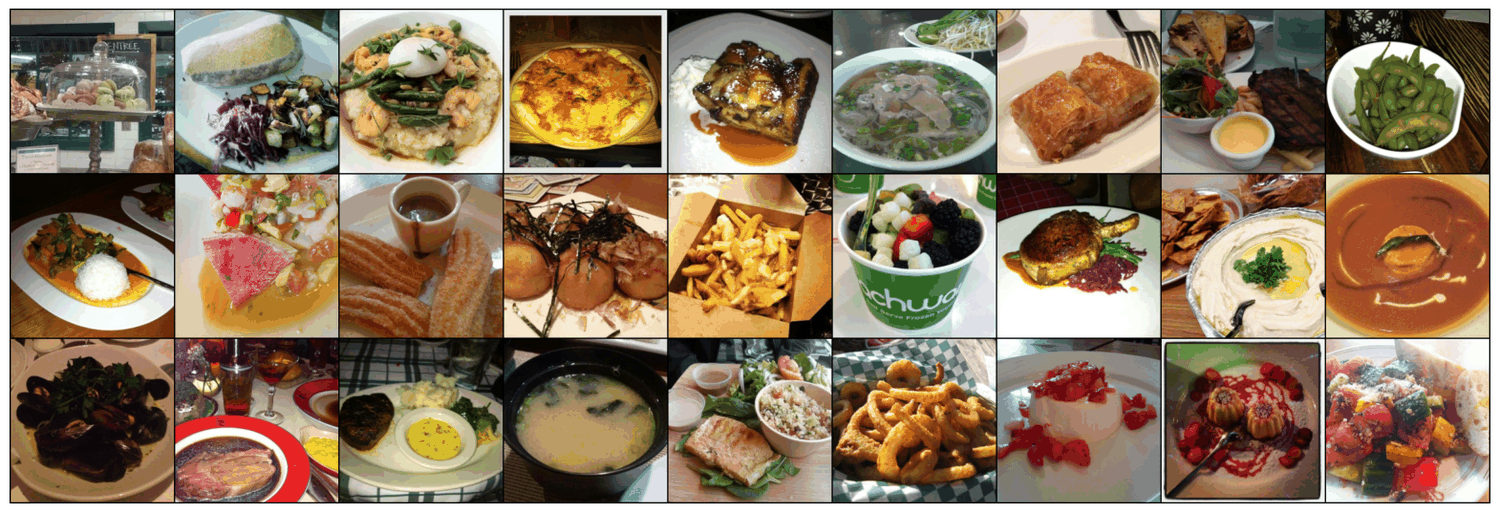

In [ ]:
sample_inputs, _ = next(iter(loader_val))
fixed_input = sample_inputs[:27, :, :, :]

img = make_grid(denorm(fixed_input), nrow=9, padding=2, normalize=False,
                value_range=None, scale_each=False, pad_value=0)
plt.figure(figsize=(20,10))
plt.axis('off')
show(img)

Next, we define ResNet-18:

In [ ]:
# define resnet building blocks

class ResidualBlock(nn.Module): 
    def __init__(self, inchannel, outchannel, stride=1): 
        
        super(ResidualBlock, self).__init__() 
        
        self.left = nn.Sequential(nn.Conv2d(inchannel, outchannel, kernel_size=3, 
                                         stride=stride, padding=1, bias=False), 
                                  nn.BatchNorm2d(outchannel), 
                                  nn.ReLU(inplace=True), 
                                  nn.Conv2d(outchannel, outchannel, kernel_size=3, 
                                         stride=1, padding=1, bias=False), 
                                  nn.BatchNorm2d(outchannel)) 
        
        self.shortcut = nn.Sequential() 
        
        if stride != 1 or inchannel != outchannel: 
            
            self.shortcut = nn.Sequential(nn.Conv2d(inchannel, outchannel, 
                                                 kernel_size=1, stride=stride, 
                                                 padding = 0, bias=False), 
                                          nn.BatchNorm2d(outchannel) ) 
            
    def forward(self, x): 
        
        out = self.left(x) 
        
        out += self.shortcut(x) 
        
        out = F.relu(out) 
        
        return out


    
# define resnet

class ResNet(nn.Module):
    
    def __init__(self, ResidualBlock, num_classes = 101):
        
        super(ResNet, self).__init__()
        
        self.inchannel = 16
        self.conv1 = nn.Sequential(nn.Conv2d(3, 16, kernel_size = 3, stride = 1,
                                            padding = 1, bias = False), 
                                  nn.BatchNorm2d(16), 
                                  nn.ReLU())
        
        self.layer1 = self.make_layer(ResidualBlock, 16, 2, stride = 2)
        self.layer2 = self.make_layer(ResidualBlock, 32, 2, stride = 2)
        self.layer3 = self.make_layer(ResidualBlock, 64, 2, stride = 2)
        self.layer4 = self.make_layer(ResidualBlock, 128, 2, stride = 2)
        self.layer5 = self.make_layer(ResidualBlock, 256, 2, stride = 2)
        self.layer6 = self.make_layer(ResidualBlock, 512, 2, stride = 2)
        self.maxpool = nn.MaxPool2d(4)
        self.fc = nn.Linear(512, num_classes)
        
    
    def make_layer(self, block, channels, num_blocks, stride):
        
        strides = [stride] + [1] * (num_blocks - 1)
        
        layers = []
        
        for stride in strides:
            
            layers.append(block(self.inchannel, channels, stride))
            
            self.inchannel = channels
            
        return nn.Sequential(*layers)
    
    
    def forward(self, x):
        
        x = self.conv1(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = self.layer6(x)
        x = self.maxpool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x
    
# please do not change the name of this class
def MyResNet():
    return ResNet(ResidualBlock)

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


def confusion(preds, y):
  with open(content_path+'/food-101/meta/labels.txt', 'r') as file:
        labels = [line.strip() for line in file if line.strip()]

  # Plotting the confusion matrix
  cm = confusion_matrix(y.cpu().numpy(), preds.cpu().numpy(), normalize='true', labels=range(len(labels)))
  fig, ax= plt.subplots(1, 1, figsize=(55,50))
  sns.heatmap(cm, annot=True, annot_kws={"size": 8}, ax=ax, cmap="Blues")

  # labels, title and ticks
  ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 
  ax.set_title('Confusion Matrix');
  ax.set_xticks(range(len(labels)), labels=labels); ax.set_yticks(range(len(labels)), labels=labels);
  ax.xaxis.set_ticklabels(labels, rotation = 90); ax.yaxis.set_ticklabels(labels, rotation=0);
  plt.show()

def incorrect_preds(preds, y, test_img):
  with open(content_path+'/food-101/meta/labels.txt', 'r') as file:
        labels = [line.strip() for line in file if line.strip()]
  # lets see a sample of the images which were classified incorrectly!
  correct = (preds == y).float()
  test_labels_check = correct.cpu().numpy()
  incorrect_indexes = np.where(test_labels_check == 0)

  test_img = test_img.cpu()
  samples = make_grid(denorm(test_img[incorrect_indexes][:9]), nrow=3,
                      padding=2, normalize=False, value_range=None, 
                      scale_each=False, pad_value=0)
  plt.figure(figsize = (20,10))
  plt.title('Incorrectly Classified Instances')
  show(samples)
  labels = np.asarray(labels)
  print('Predicted label',labels[preds[incorrect_indexes].cpu().numpy()[:9]])
  print('True label', labels[y[incorrect_indexes].cpu().numpy()[:9]])
  print('Corresponding images are shown below')

In [ ]:
print(torch.cuda.is_available()) # Should return True
print(torch.device('cuda:0'))

True
cuda:0


In [ ]:
USE_GPU = True
dtype = torch.float32 


if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

print(device)
    

print_every = 10
def check_accuracy(loader, model, analysis=False, hotdog_data=False):
    # function for test accuracy on validation and test set
    
    num_correct = 0
    num_samples = 0
    target_class_correct = 0
    target_class_samples = 0
    target_class = 55 #hot dogs
    model.eval()  # set model to evaluation mode
    with torch.no_grad():
        for t, (x, y) in enumerate(loader):
            x = x.to(device=device, dtype=dtype)  # move to device
            if hotdog_data:
                y = torch.tensor(target_class).repeat(x.shape[0]).to(device=device, dtype=torch.long)
            else:
                y = y.to(device=device, dtype=torch.long)
            scores = model(x)
            _, preds = scores.max(1)
            num_correct += (preds == y).sum()
            num_samples += preds.size(0)
            mask = (y == target_class)  # Filter for target class
            if mask.sum() > 0:  # Ensure there are samples of the target class
                target_class_correct += (preds[mask] == y[mask]).sum()
                target_class_samples += mask.sum()
                
            if t == 0 and analysis:
              stack_labels = y
              stack_predicts = preds
            elif analysis:
              stack_labels = torch.cat([stack_labels, y], 0)
              stack_predicts = torch.cat([stack_predicts, preds], 0)
        acc = float(num_correct) / num_samples
        print('Got %d / %d correct of val set (%.2f)' % (num_correct, num_samples, 100 * acc))
        
        # Calculate accuracy for the target class
        if target_class_samples > 0:
            target_class_acc = float(target_class_correct) / target_class_samples
            print('Got %d / %d correct Hot Dogs (class %d) (%.2f%%)' % (
                target_class_correct, target_class_samples, target_class, 100 * target_class_acc))
        else:
            target_class_acc = 0.0
            print(f'No samples found for class {target_class}.')
            
        if analysis:
          print('check acc', type(stack_predicts), type(stack_labels))
          confusion(stack_predicts, stack_labels)
          incorrect_preds(preds, y, x)
        return float(acc)

        

def train_part(model, optimizer, epochs=1):
    """
    Train a model on food101 using the PyTorch Module API.
    
    Inputs:
    - model: A PyTorch Module giving the model to train.
    - optimizer: An Optimizer object we will use to train the model
    - epochs: (Optional) A Python integer giving the number of epochs to train for
    
    Returns: Nothing, but prints model accuracies during training.
    """
    model = model.to(device=device)  # move the model parameters to CPU/GPU
    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # put model to training mode
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = F.cross_entropy(scores, y)

            # Zero out all of the gradients for the variables which the optimizer
            # will update.
            optimizer.zero_grad()

            loss.backward()

            # Update the parameters of the model using the gradients
            optimizer.step()

            if t % print_every == 0:
                print('Epoch: %d, Iteration %d, loss = %.4f' % (e, t, loss.item()))
        check_accuracy(loader_val, model)

cuda:0


## Baseline

[... earlier log lines omitted ...]
Epoch: 8, Iteration 520, loss = 1.0185
Epoch: 8, Iteration 530, loss = 1.0148
Got 937 / 7575 correct of val set (12.37)
Got 3 / 63 correct Hot Dogs (class 55) (4.76%)
Epoch: 9, Iteration 0, loss = 0.4933
Epoch: 9, Iteration 10, loss = 0.6434
Epoch: 9, Iteration 20, loss = 0.6644
Epoch: 9, Iteration 30, loss = 0.5266
Epoch: 9, Iteration 40, loss = 0.4967
Epoch: 9, Iteration 50, loss = 0.5840
Epoch: 9, Iteration 60, loss = 0.6224
Epoch: 9, Iteration 70, loss = 0.5230
Epoch: 9, Iteration 80, loss = 1.5271
Epoch: 9, Iteration 90, loss = 0.9106
Epoch: 9, Iteration 100, loss = 0.5189
Epoch: 9, Iteration 110, loss = 0.5473
Epoch: 9, Iteration 120, loss = 1.1314
Epoch: 9, Iteration 130, loss = 0.5174
Epoch: 9, Iteration 140, loss = 0.7638
Epoch: 9, Iteration 150, loss = 0.8529
Epoch: 9, Iteration 160, loss = 0.5093
Epoch: 9, Iteration 170, loss = 1.1432
Epoch: 9, Iteration 180, loss = 0.5461
Epoch: 9, Iteration 190, loss = 0.7415
Epoch: 9, Iteration 200, los

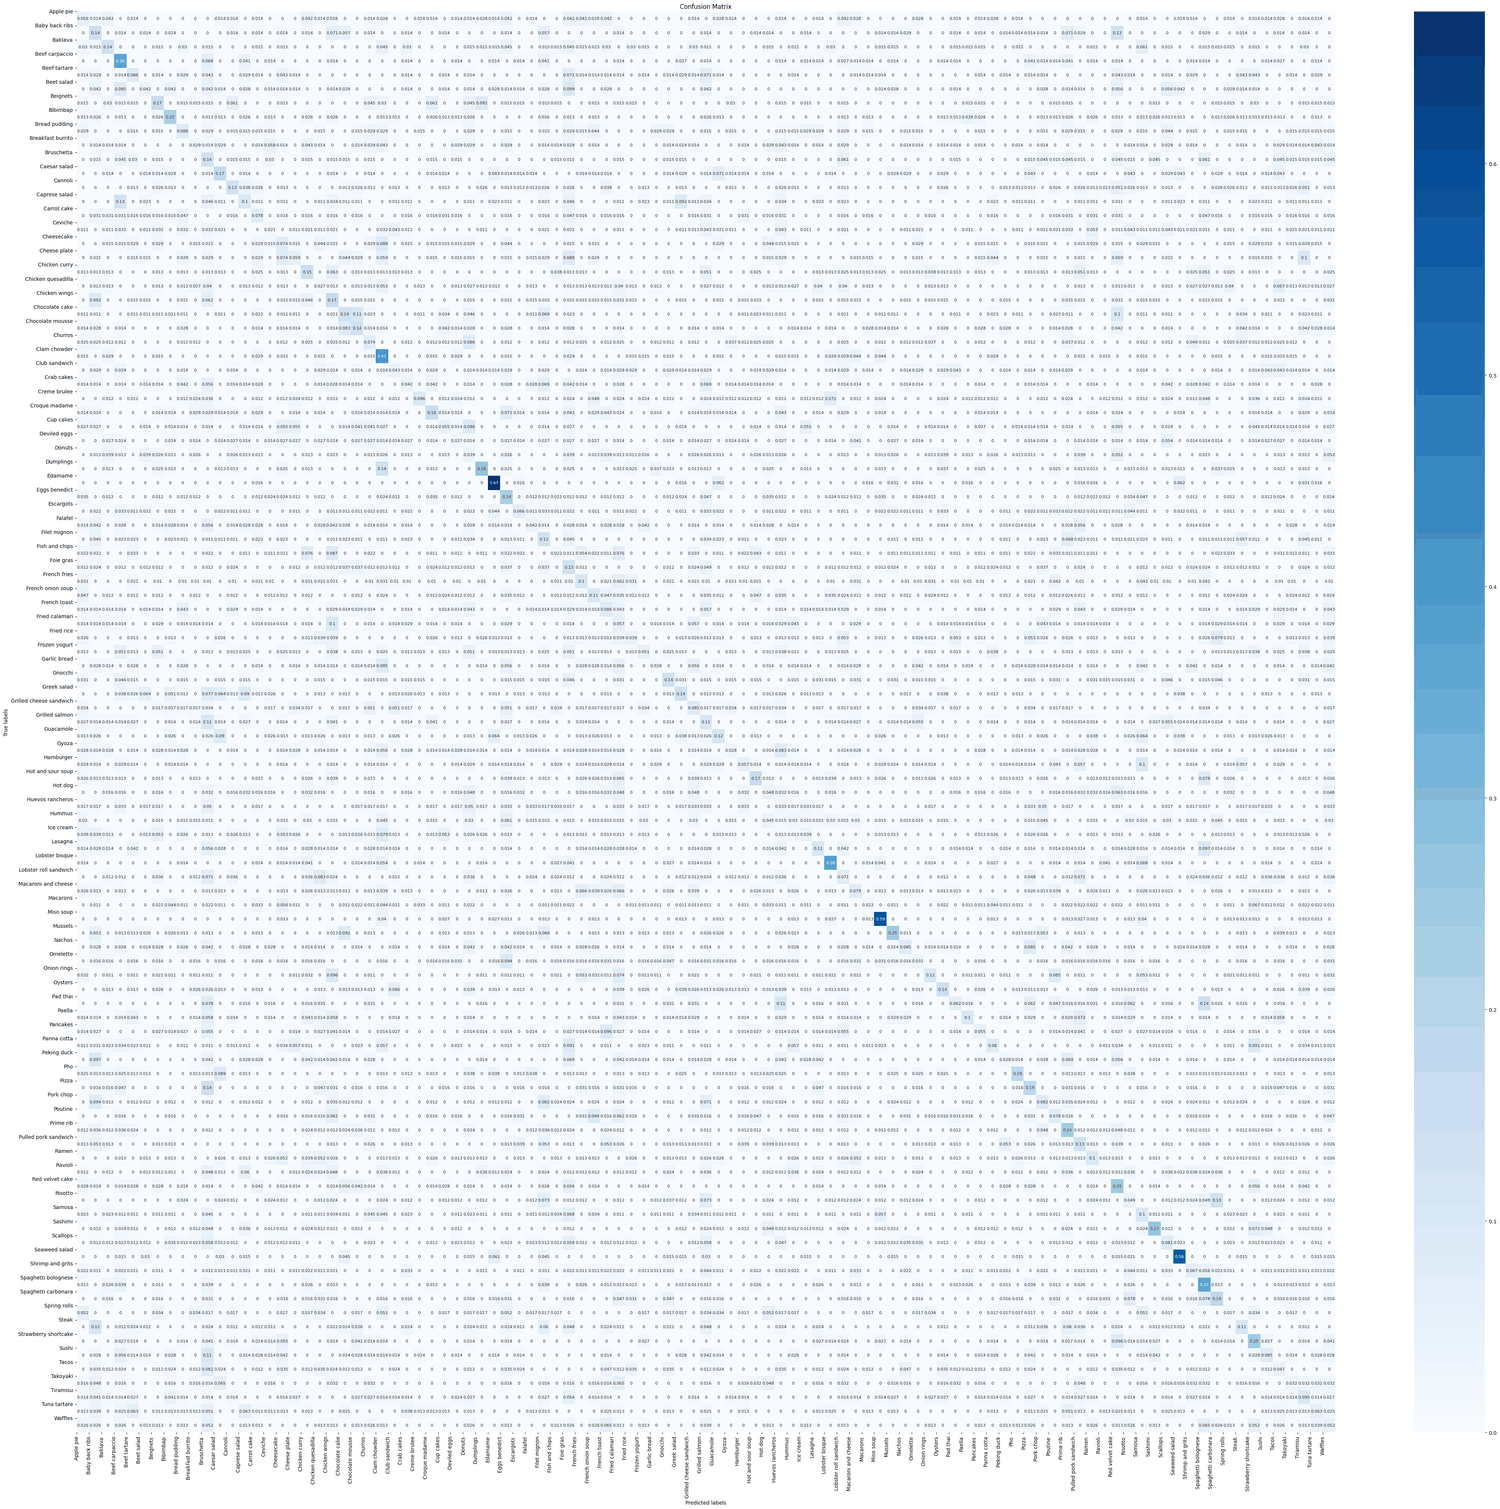

Predicted label ['Scallops' 'French onion soup' 'Edamame' 'Prime rib' 'Beef carpaccio'
 'Greek salad' 'French onion soup' 'Gnocchi' 'Lobster roll sandwich']
True label ['Beet salad' 'Pizza' 'Oysters' 'Steak' 'Prime rib' 'Ramen' 'Pork chop'
 'Fried calamari' 'French toast']
Corresponding images are shown below


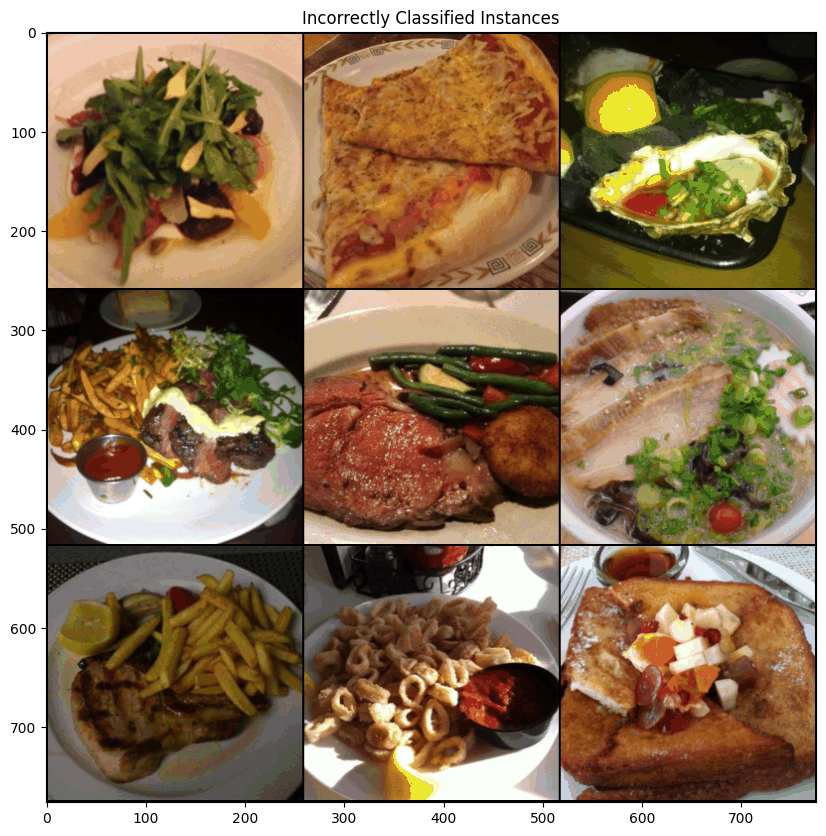

In [ ]:
# define and train the network
model = MyResNet()
optimizer = optim.Adamax(model.parameters(), lr=0.0001, weight_decay=1e-7) 

params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total number of parameters is: {}".format(params))

train_part(model, optimizer, epochs = 10)


# report validation set accuracy
check_accuracy(loader_val, model, analysis=True)


# save the model
torch.save(model.state_dict(), 'baseline_model.pt')

In [ ]:
# Load the saved weights into the model
baseline_model = MyResNet()
baseline_model.load_state_dict(torch.load('baseline_model.pt'))
baseline_model = model.to(device=device)  # move the model parameters to CPU/GPU

Got 3388 / 25250 correct of val set (13.42)
Got 14 / 250 correct Hot Dogs (class 55) (5.60%)
check acc <class 'torch.Tensor'> <class 'torch.Tensor'>


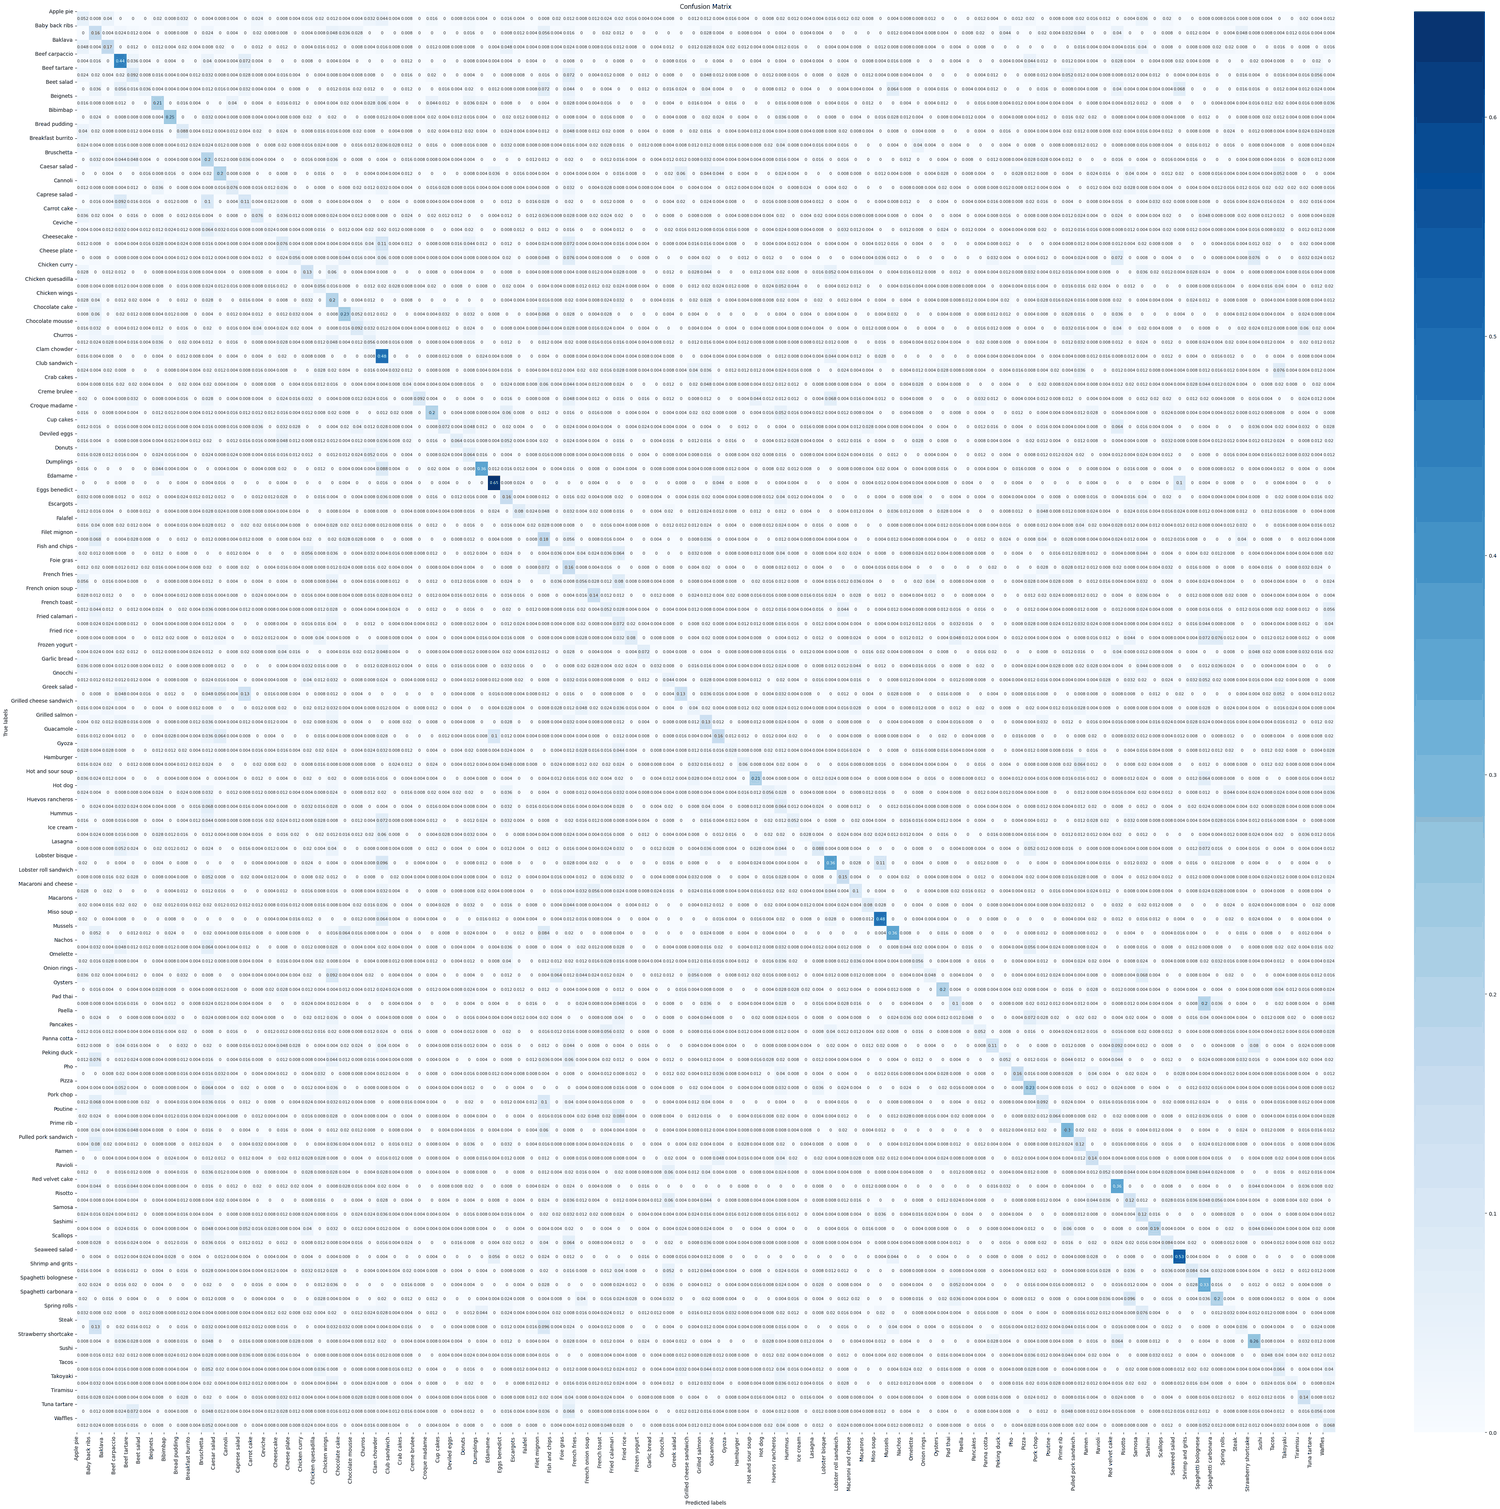

Predicted label ['Grilled cheese sandwich' 'Cup cakes' 'Hot dog' 'Caprese salad' 'Mussels'
 'Nachos' 'Croque madame' 'Paella' 'Oysters']
True label ['Hot dog' 'Ravioli' 'Prime rib' 'Club sandwich' 'Falafel' 'Caprese salad'
 'Hamburger' 'Ravioli' 'Tiramisu']
Corresponding images are shown below


0.1341782178217822

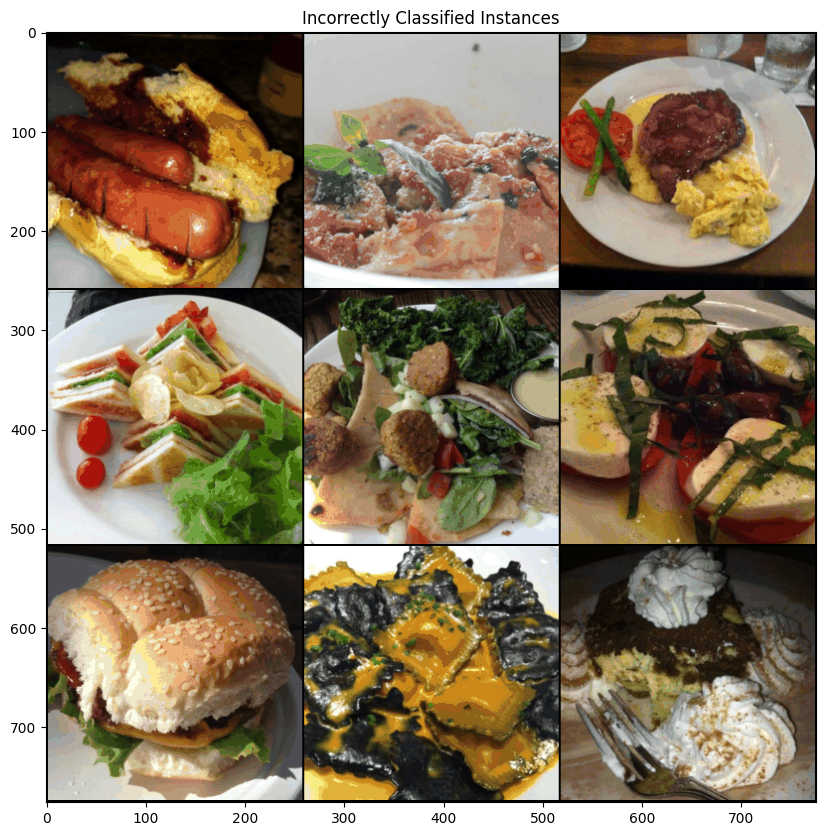

In [ ]:
check_accuracy(loader_test, baseline_model, analysis=True)

---

Got 3431 / 25250 correct of val set (13.59)
Got 27 / 250 correct Hot Dogs (class 55) (10.80%)
check acc <class 'torch.Tensor'> <class 'torch.Tensor'>


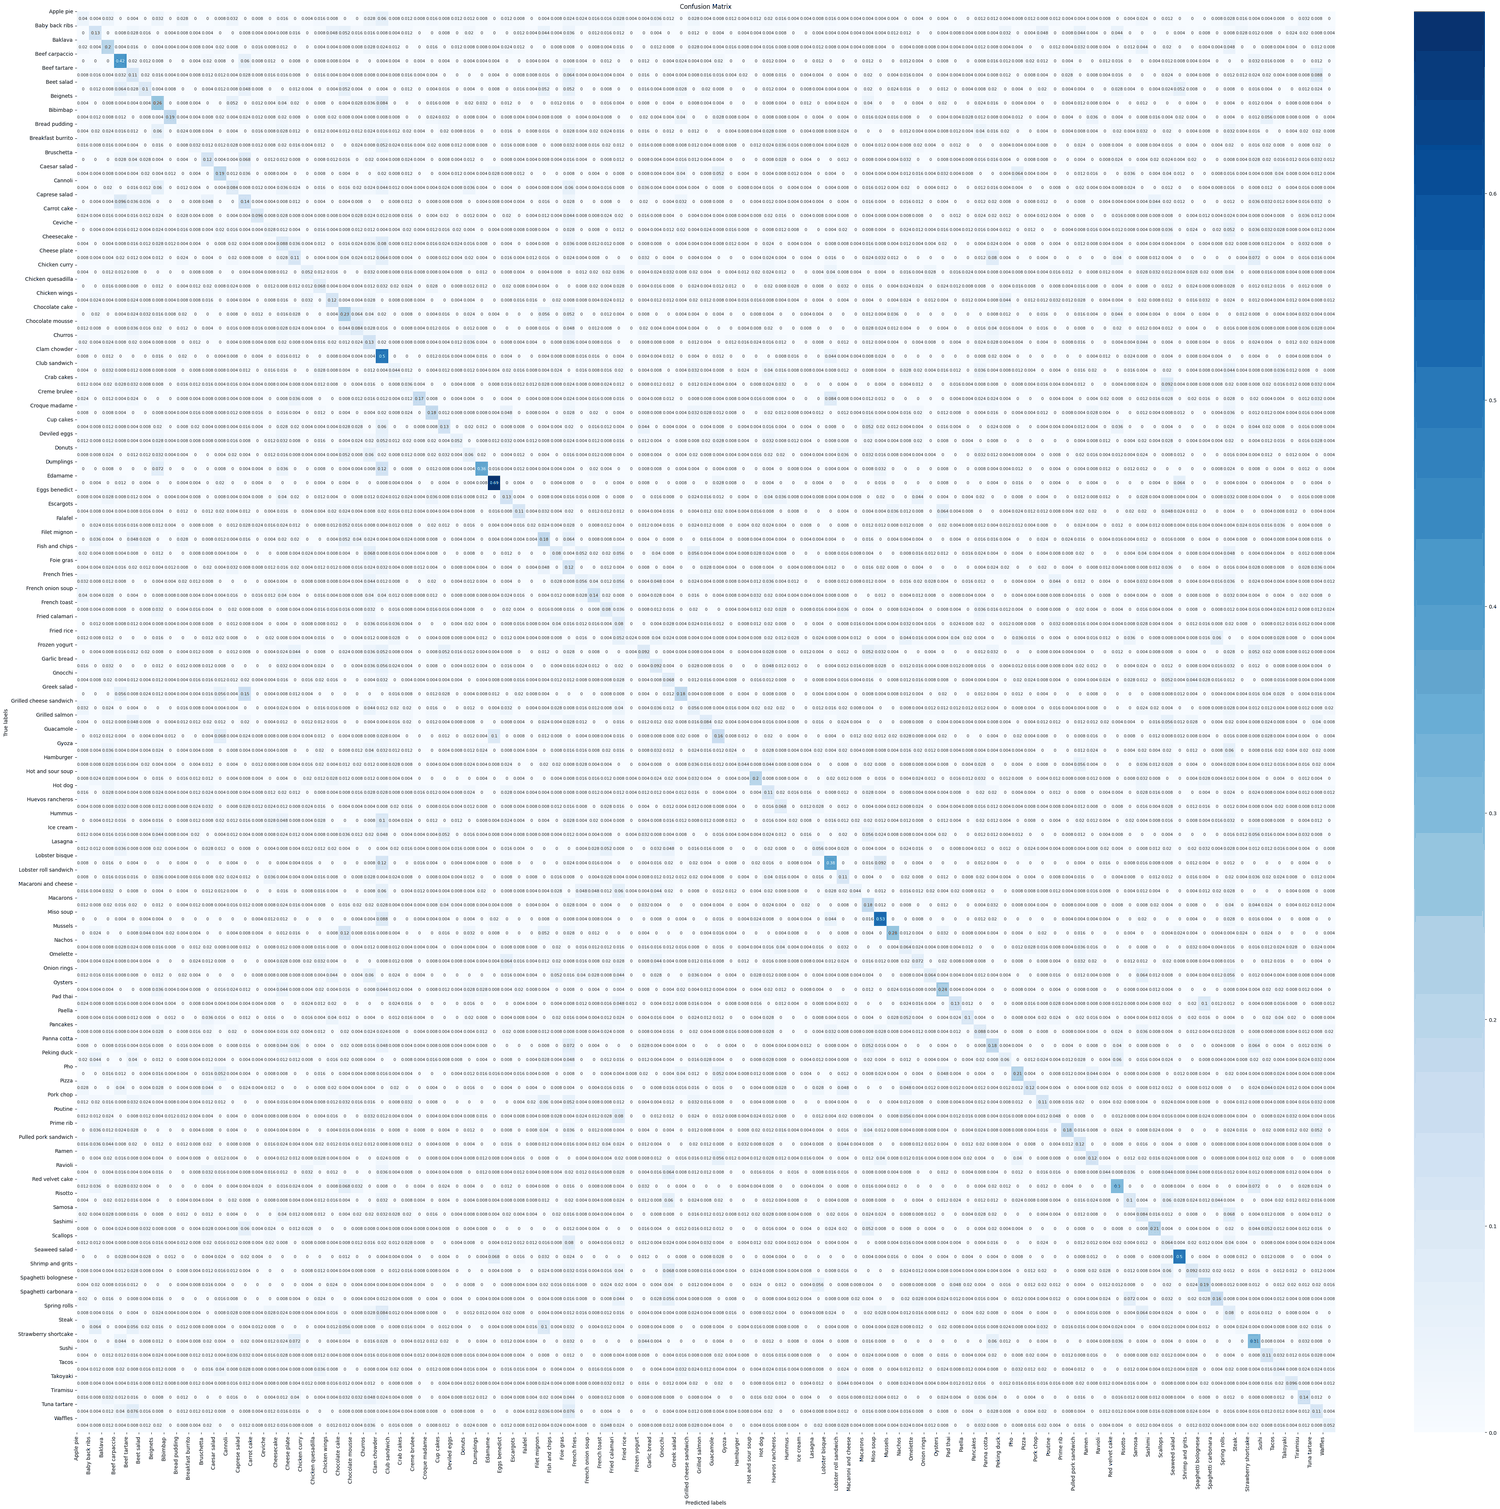

Predicted label ['Churros' 'Scallops' 'Spaghetti carbonara' 'Creme brulee'
 'Breakfast burrito' 'Lasagna' 'Red velvet cake' 'Scallops' 'Foie gras']
True label ['Poutine' 'Macarons' 'Fried rice' 'Apple pie' 'Scallops' 'Gnocchi'
 'French toast' 'Poutine' 'Donuts']
Corresponding images are shown below


0.1358811881188119

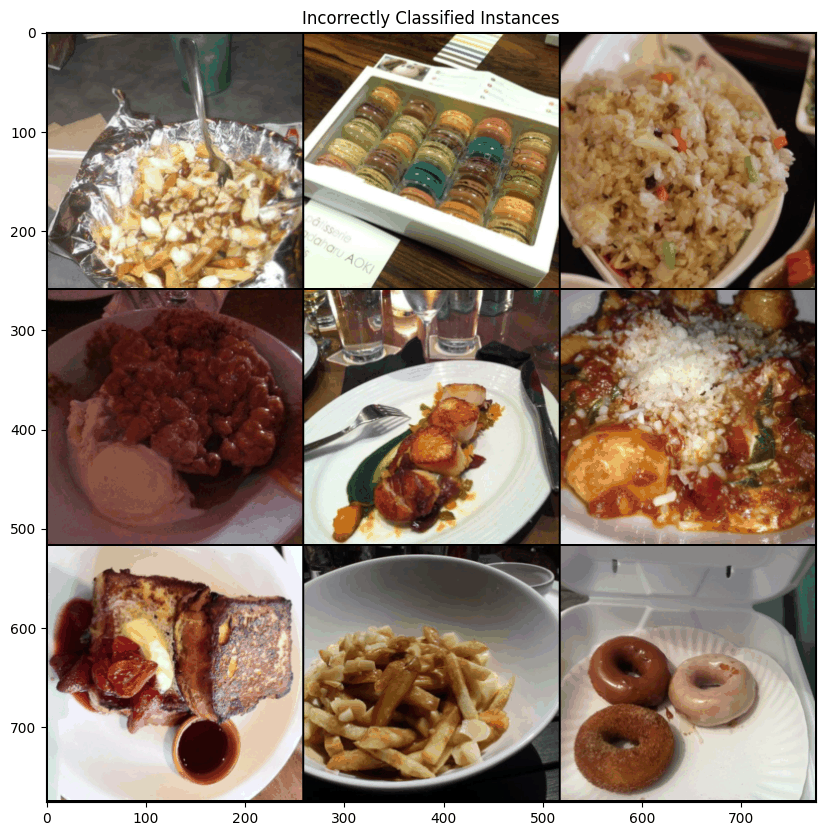

In [ ]:
# Test set accuracy of the baseline model
check_accuracy(loader_test, model, analysis=True)

___

## My Modifications

### Improving Architecture

In [ ]:
class ImprovedResNet(nn.Module):
   
    def __init__(self, block, num_classes=101):
        super(ImprovedResNet, self).__init__()
        
        self.inchannel = 64
        
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        
        self.layer1 = self.make_layer(block, 64, 2, stride=1)
        self.layer2 = self.make_layer(block, 128, 2, stride=2)
        self.layer3 = self.make_layer(block, 256, 2, stride=2)
        self.layer4 = self.make_layer(block, 512, 2, stride=2)
        
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512, num_classes)        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def make_layer(self, block, channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.inchannel, channels, stride))
            self.inchannel = channels
        return nn.Sequential(*layers)
    
    def forward(self, x):
        x = self.conv1(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

def MyImprovedResNet():
    return ImprovedResNet(ResidualBlock)

### Data Augmentation

In [ ]:
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader

mean = torch.Tensor([0.485, 0.456, 0.406])
std = torch.Tensor([0.229, 0.224, 0.225])

# Training transforms with augmentation
transform_train_final = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

# Validation transforms without augmentation
transform_val_final = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

train_path = content_path + '/food-101/train'
test_path = content_path + '/food-101/test'

train_dataset_final = datasets.ImageFolder(train_path, transform=transform_train_final)
train_dataset_val_final = datasets.ImageFolder(train_path, transform=transform_val_final)
test_dataset_final = datasets.ImageFolder(test_path, transform=transform_val_final)

# Split into train and validation sets
n = len(train_dataset_final)
n_val = int(n / 10)
indices = list(range(n))
train_indices, val_indices = torch.utils.data.random_split(
    indices, [n - n_val, n_val], 
    generator=torch.Generator().manual_seed(90)
)

train_set_final = torch.utils.data.Subset(train_dataset_final, train_indices.indices)
val_set_final = torch.utils.data.Subset(train_dataset_val_final, val_indices.indices)

# Data loaders
batch_size = 128

loader_train_final = DataLoader(train_set_final, batch_size=batch_size, shuffle=True,
                               num_workers=num_workers, pin_memory=True)
loader_val_final = DataLoader(val_set_final, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True)
loader_test_final = DataLoader(test_dataset_final, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=True)

print(f"Data loaders got ready: Batch={batch_size}, Train={len(train_set_final)}, Val={len(val_set_final)}")

Data loaders got ready: Batch=128, Train=68175, Val=7575


### Training with checkpoints, as training was interrupted several times

The model, optimiser, scheduler and history are saved every epoch.

In [ ]:
import json
import os

def train_with_checkpoints(model, optimizer, scheduler, epochs=40, patience=10, checkpoint_path='checkpoint.pt'):
    model = model.to(device=device)
    
    start_epoch = 0
    history = {'train_loss': [], 'val_acc': [], 'learning_rates': []}
    best_val_acc = 0.0
    patience_counter = 0

    # option to resume from the last checkpoint if training was interrupted
    if os.path.exists(checkpoint_path):
        print(f"found checkpoint: {checkpoint_path}")
        resume = input("Resume?")
        if resume.lower() == 'yes':
            ckpt = torch.load(checkpoint_path)
            model.load_state_dict(ckpt['model'])
            optimizer.load_state_dict(ckpt['optimizer'])
            scheduler.load_state_dict(ckpt['scheduler'])
            start_epoch = ckpt['epoch'] + 1
            history = ckpt['history']
            best_val_acc = ckpt['best_val_acc']
            patience_counter = ckpt['patience_counter']
            print(f"resumed from epoch {start_epoch}, best val: {best_val_acc*100:.2f}%")
    
    print(f"training epochs {start_epoch} to {epochs}, patience={patience}")
    print("******************************************************")
    
    for epoch in range(start_epoch, epochs):
        # training
        model.train()
        epoch_loss = 0.0
        num_batches = 0
        
        for batch_idx, (x, y) in enumerate(loader_train_final):
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=torch.long)
            
            scores = model(x)
            loss = F.cross_entropy(scores, y)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            num_batches += 1
            
            if batch_idx % 100 == 0:
                print(f'Epoch {epoch:2d}/{epochs}, Batch {batch_idx:3d}, '
                      f'Loss: {loss.item():.4f}, Learning Rate: {optimizer.param_groups[0]["lr"]:.6f}')
        
        avg_loss = epoch_loss / num_batches
        
        # validation
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in loader_val_final:
                x = x.to(device=device, dtype=dtype)
                y = y.to(device=device, dtype=torch.long)
                scores = model(x)
                _, pred = scores.max(1)
                total += y.size(0)
                correct += (pred == y).sum().item()
        
        val_acc = correct / total
        
        # update history
        history['train_loss'].append(avg_loss)
        history['val_acc'].append(val_acc)
        history['learning_rates'].append(optimizer.param_groups[0]['lr'])
        
        print("******************************************************")
        print(f'Epoch {epoch:2d}: Loss={avg_loss:.4f}, Validation Accuracy={val_acc*100:.2f}%, Learning Rate={optimizer.param_groups[0]["lr"]:.6f}')
        
        # save the best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), 'best_model_final.pt')
            print(f'there is a new best result ({val_acc*100:.2f}%) saved!')
        else:
            patience_counter += 1
            print(f'no improvement for {patience_counter} epochs. patience: {patience}')
        
        # save checkpoint
        torch.save({
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'history': history,
            'best_val_acc': best_val_acc,
            'patience_counter': patience_counter
        }, checkpoint_path)
        
        # save the history for plotting
        with open('history.json', 'w') as f:
            json.dump(history, f)
        
        print(f'checkpoint saved.')
        print(f'-------------------------------')
        
        # early stopping
        if patience_counter >= patience:
            print(f'early stopping at epoch {epoch}. best accuracy: {best_val_acc*100:.2f}%')
            break
        
        scheduler.step()
    
    # load the best model
    model.load_state_dict(torch.load('best_model_final.pt'))
    print(f'\nTraining finished. Best val acc: {best_val_acc*100:.2f}%')
    return model, history

### Setup & Training

In [ ]:
model_final = MyImprovedResNet()
model_final = model_final.to(device=device)

print(f"the parameters are: {sum(p.numel() for p in model_final.parameters()):,}")

# optimizer
optimizer_final = torch.optim.AdamW(
    model_final.parameters(), lr=0.001, weight_decay=1e-3
)

# scheduler
epochs_final = 40
scheduler_final = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_final, T_max=epochs_final, eta_min=1e-6
)

# Train
model_final, history_final = train_with_checkpoints(
    model_final, optimizer_final, scheduler_final,
    epochs=40, patience=10, checkpoint_path='checkpoint.pt'
)

[... earlier log lines omitted ...]
checkpoint saved.
-------------------------------
Epoch 36/40, Batch   0, Loss: 0.5836, Learning Rate: 0.000025
Epoch 36/40, Batch 100, Loss: 0.4606, Learning Rate: 0.000025
Epoch 36/40, Batch 200, Loss: 0.5838, Learning Rate: 0.000025
Epoch 36/40, Batch 300, Loss: 0.6235, Learning Rate: 0.000025
Epoch 36/40, Batch 400, Loss: 0.4500, Learning Rate: 0.000025
Epoch 36/40, Batch 500, Loss: 0.5320, Learning Rate: 0.000025
******************************************************
Epoch 36: Loss=0.5706, Validation Accuracy=65.16%, Learning Rate=0.000025
no improvement for 1 epochs. patience: 10
checkpoint saved.
-------------------------------
Epoch 37/40, Batch   0, Loss: 0.5700, Learning Rate: 0.000015
Epoch 37/40, Batch 100, Loss: 0.5923, Learning Rate: 0.000015
Epoch 37/40, Batch 200, Loss: 0.6003, Learning Rate: 0.000015
Epoch 37/40, Batch 300, Loss: 0.6133, Learning Rate: 0.000015
Epoch 37/40, Batch 400, Loss: 0.6058, Learning Rate: 0.000015
Epoch 37/40

<a id="viz"></a>
### Visualization

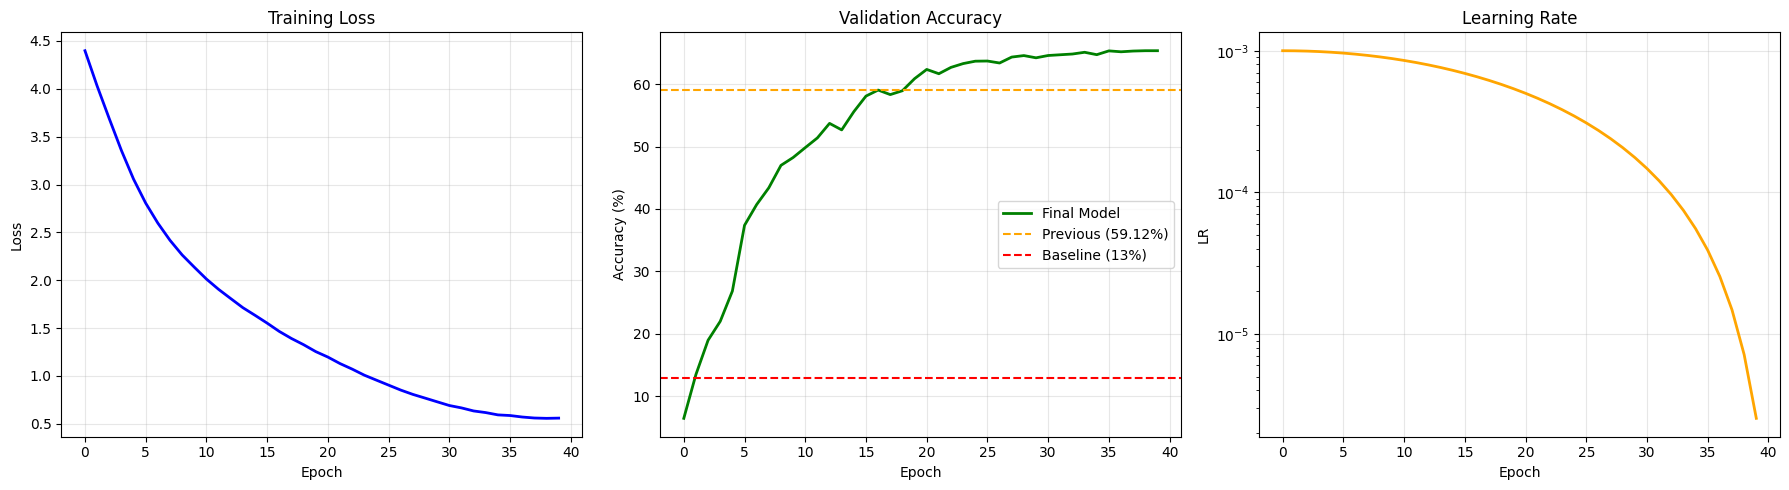


Best Val Acc: 65.33%


In [ ]:
import matplotlib.pyplot as plt
import json
import os

# load the history saved during training
if os.path.exists('history.json'):
    with open('history.json') as f:
        history_final = json.load(f)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# plotting loss
axes[0].plot(history_final['train_loss'], 'b-', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].grid(True, alpha=0.3)

# plotting accuracy
val_acc = [a*100 for a in history_final['val_acc']]
axes[1].plot(val_acc, 'g-', linewidth=2, label='Final Model')
axes[1].axhline(y=59.12, color='orange', linestyle='--', label='Previous (59.12%)')
axes[1].axhline(y=13, color='red', linestyle='--', label='Baseline (13%)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# plotting learning rate
axes[2].plot(history_final['learning_rates'], 'orange', linewidth=2)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('LR')
axes[2].set_title('Learning Rate')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

# summary
best = max(history_final['val_acc'])
print(f"\nBest Val Acc: {best*100:.2f}%")

### Network performance

### Test set evaluation

Test Accuracy: 70.96%
Got 17918 / 25250 correct of val set (70.96)
Got 173 / 250 correct Hot Dogs (class 55) (69.20%)
check acc <class 'torch.Tensor'> <class 'torch.Tensor'>


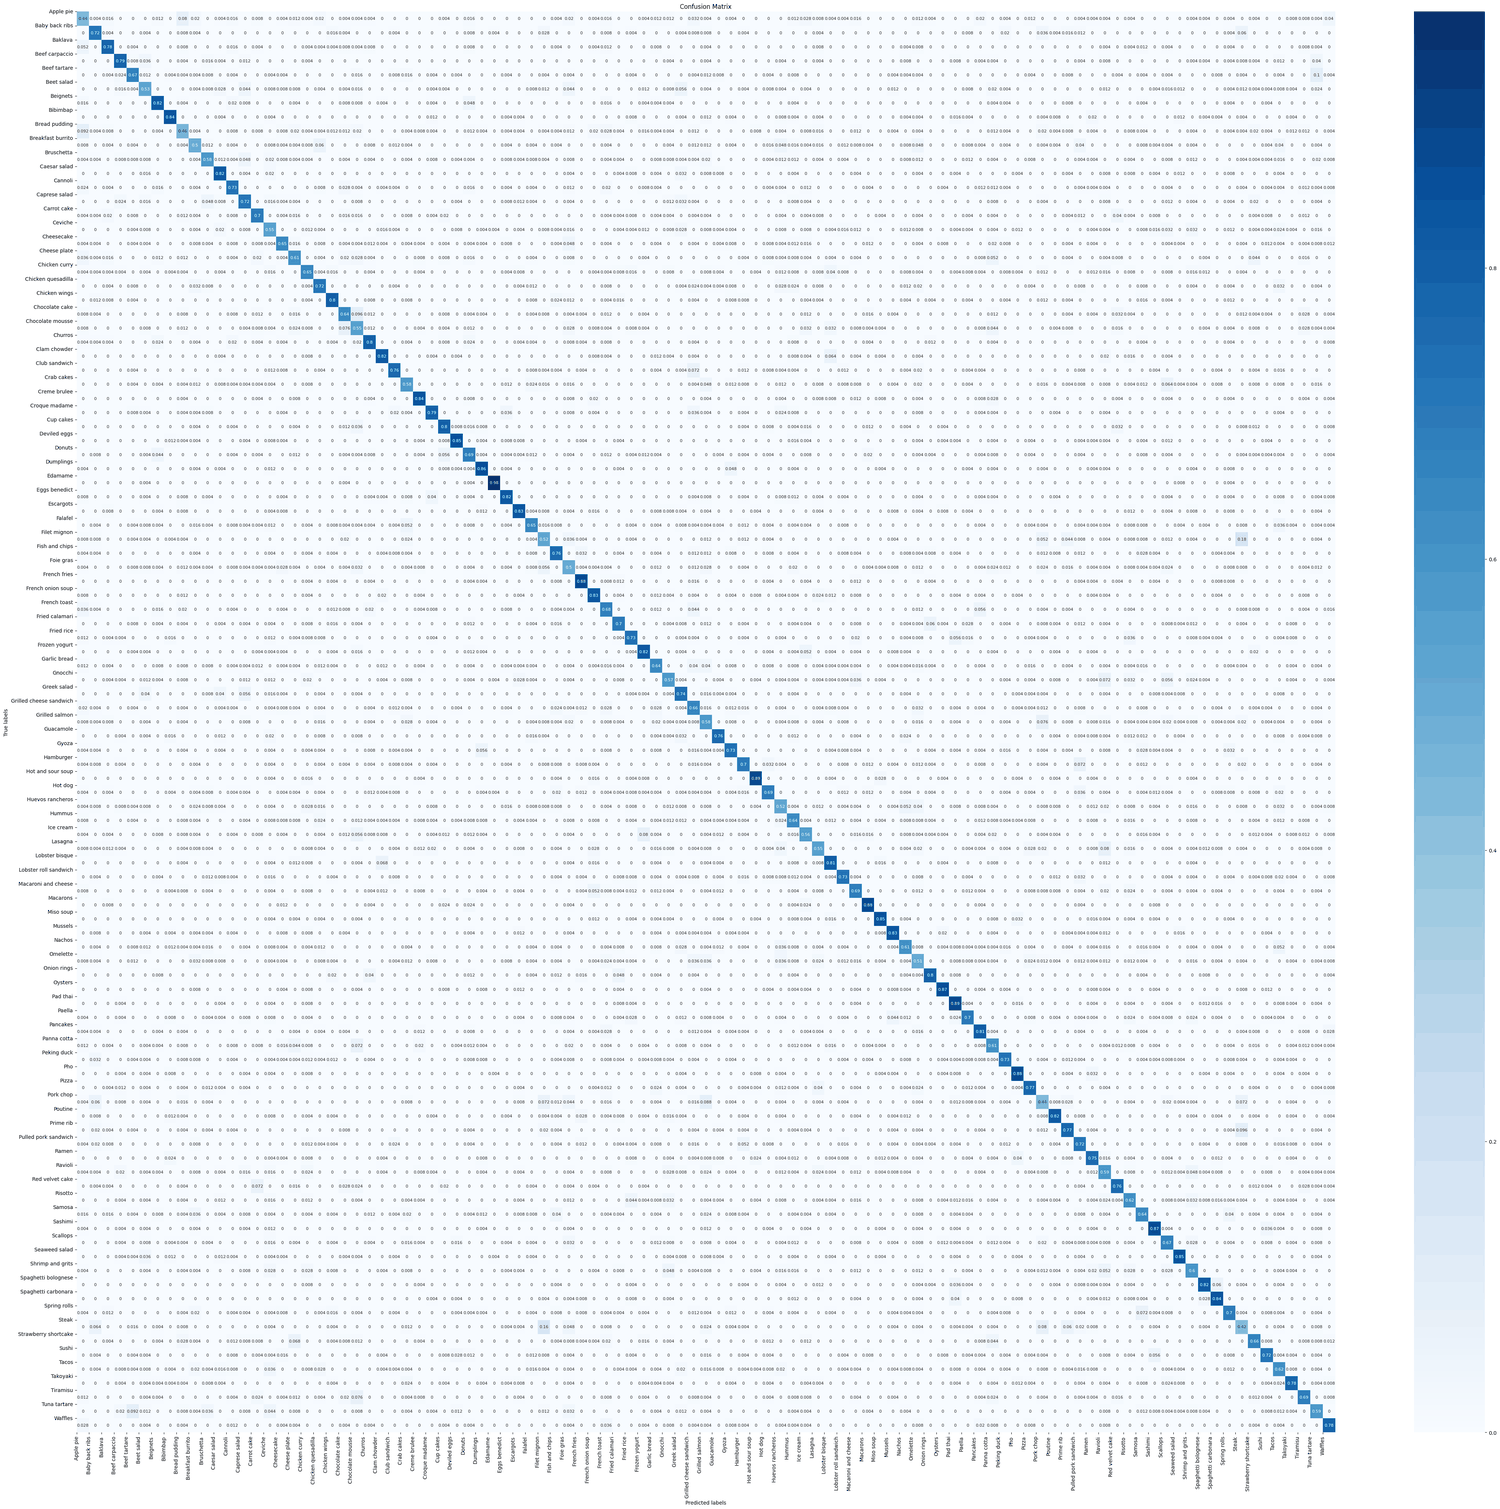

Predicted label ['Apple pie' 'Pancakes' 'Cannoli' 'Omelette' 'Panna cotta' 'Apple pie'
 'Grilled cheese sandwich' 'French toast' 'Frozen yogurt']
True label ['Waffles' 'Waffles' 'Waffles' 'Waffles' 'Waffles' 'Waffles' 'Waffles'
 'Waffles' 'Waffles']
Corresponding images are shown below


0.7096237623762376

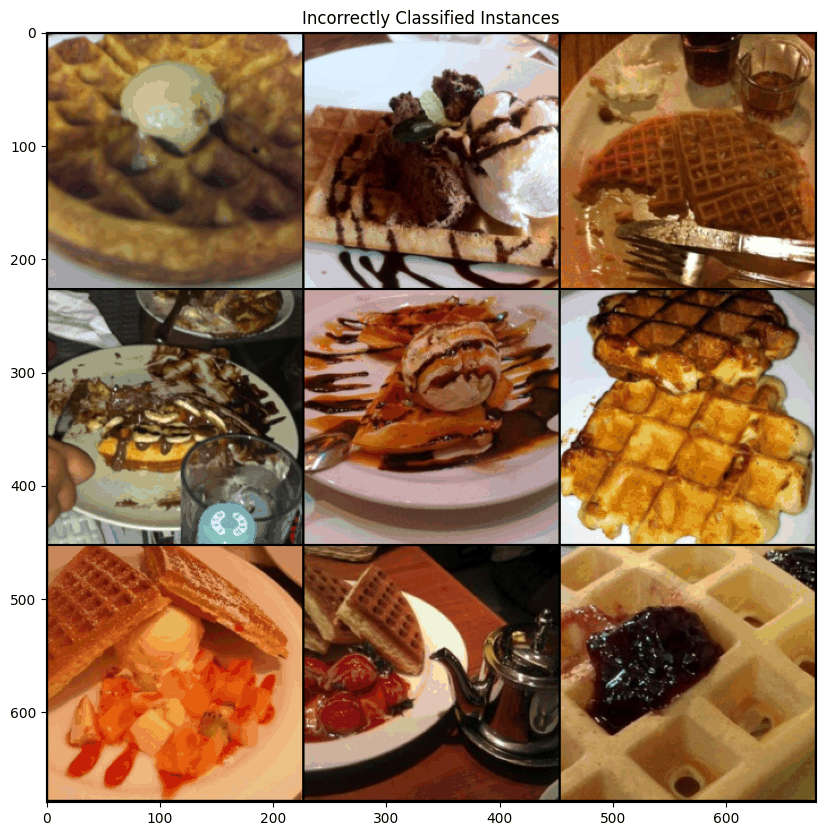

In [ ]:
model_final.load_state_dict(torch.load('best_model_final.pt'))
model_final.eval()

test_correct, test_total = 0, 0

with torch.no_grad():
    for x, y in loader_test_final:
        x = x.to(device=device, dtype=dtype)
        y = y.to(device=device, dtype=torch.long)
        scores = model_final(x)
        _, pred = scores.max(1)
        test_total += y.size(0)
        test_correct += (pred == y).sum().item()

test_acc = test_correct / test_total

print(f"Test Accuracy: {test_acc*100:.2f}%")

check_accuracy(loader_test_final, model_final, analysis=True)

### Q2.1: Engineering decisions

**Answer:**

- [x] 1. Data augmentation was used to increase the size and diversity of the training dataset.
- [ ] 2. Implemented a custom ResNet variant similar in depth to ResNet50.
- [ ] 3. LeakyReLU activation was chosen to address the Dying ReLU problem.
- [ ] 4. Randomized search was used to tune hyperparameters, testing 20 combinations.
- [ ] 5. A k-fold cross-validation randomized search was used for hyperparameter tuning.
- [x] 6. A cosine annealing learning rate scheduler was used to improve accuracy.
- [x] 7. The weight decay value is 1e-3.
- [x] 8. The batch size for training was 128.
- [x] 9. Dropout was used to improve regularization.
- [ ] 10. Batch normalization was used instead of dropout for regularization.
- [x] 11. I increased the number of epochs, and also early stopping was implemented to prevent overfitting.
- [x] 12. The model achieved 65.33% accuracy on the validation set after training for 40 epochs.
- [ ] 13. The learning rate was kept constant throughout training.
- [ ] 14. ImageNet AutoAugment was used for data augmentation.
- [x] 15. Data augmentation transformations were manually defined.
- [ ] 16. The final model architecture included max pooling layers after each convolutional block.
- [x] 17. Global average pooling was used in the final layer instead of max pooling.
- [ ] 18. The training dataset was expanded to include 200 additional classes.
- [x] 19. Increasing the number of epochs improved model accuracy (used early stopping as well). 
- [ ] 20. The model achieved a plateau in validation accuracy, indicating overfitting.
- [ ] 21. The labels were converted to binary classification (Hot Dog/No Hot Dog) to improve only Hot Dog detection accuracy.


Added: 

- [x] 22. AdamW optimizer was used instead of standard Adam/SGD to achieve better generalization through decoupled weight decay.
- [x] 23. A deeper and wider ResNet-based architecture with increased initial channels (64) was implemented to improve feature representation.


**Training & setup:**
- Instead of using a constant learning rate, I applied a cosine annealing learning rate scheduler. This gradually decreases the learning rate during training, allowing larger updates in early epochs and finer adjustments in later stages.
- This approach helps the optimizer explore the parameter space initially and then converge smoothly to a good minimum. In practice, it led to more stable training and improved final validation accuracy.
- I implemented early stopping based on validation accuracy with a patience of 10 epochs. This prevents unnecessary training when performance stops improving and reduces the risk of overfitting.

**Data Augmentation:**
- I applied random resized crops, horizontal flips, rotations, colour jitter, and affine transformations during training.
- These augmentations increased data diversity and reduced overfitting.
- Deterministic preprocessing was used for validation to ensure fair evaluation.

**Architecture:**
- I extended the baseline model to a wider and moderately deeper ResNet-style architecture with four residual stages and increased initial channels (64). I chose a ResNet-style design because residual connections help mitigate the vanishing gradient problem and make it easier to train deeper networks.
- At the input stage, I used a 7×7 convolution followed by max pooling, which is commonly used for 224×224 images and allows the network to efficiently extract low-level features while reducing spatial resolution early.
- I also replaced a large fully connected feature map with global average pooling. This significantly reduces the number of parameters in the classifier, lowers the risk of overfitting, and encourages the network to learn spatially distributed features rather than relying on specific locations.

**Regularization:**

- I used Batch Normalization to stabilise training and improve convergence.
- I added dropout (p = 0.5) before the final classifier to reduce overfitting.
- I used AdamW with weight decay (1e-3) for effective regularisation and better generalisation.
- I used a batch size of 128 to ensure stable gradients and efficient GPU usage.


Baseline accuracy: 13.59%

New accuracy after extension: 70.96% (on test set)

### Q2.2: Out of distribution evaluation

In [ ]:
if not os.path.exists('icl_dl_cw2_utils'):
    !git clone -q https://github.com/bkainz/icl_dl_cw2_utils

In [ ]:
from icl_dl_cw2_utils.utils.hotdogdataset import DLHotDogDataset
from torch.utils.data import DataLoader, sampler
image_size_ = 256
batch_size = 128

mean = torch.Tensor([0.485, 0.456, 0.406]) # assuming same dist as imagenet
std = torch.Tensor([0.229, 0.224, 0.225])

transform = transforms.Compose(
        [
            transforms.Resize(256),
            transforms.CenterCrop(256),
            transforms.ToTensor(),
            transforms.Normalize(mean.tolist(), std.tolist()),
        ]

    )

synth_hotdog_dataset = DLHotDogDataset(root=content_path, transform=transform, split='test', preload=True)

print(len(synth_hotdog_dataset))

synth_hotdog_loader = DataLoader(synth_hotdog_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)

52656it [00:02, 24454.76it/s]


1it [00:00, 11491.24it/s]


Expected MD5: 5d2760cc722333db66653b1d3dbf2948
Computed MD5: 5d2760cc722333db66653b1d3dbf2948
MD5 verification result: True
Renaming files in hot-dog-10k_c...
Renaming complete.
number of hot dogs:  1000
1000


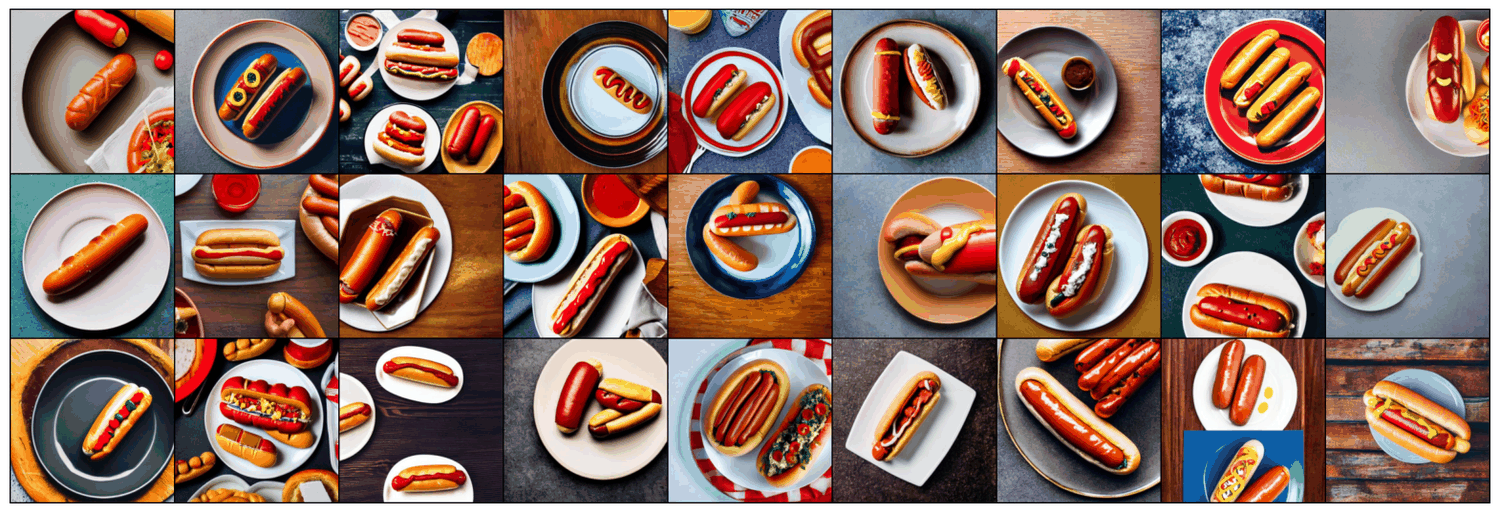

In [ ]:
sample_inputs, _ = next(iter(synth_hotdog_loader))
fixed_input = sample_inputs[:27, :, :, :]

img = make_grid(denorm(fixed_input), nrow=9, padding=2, normalize=False,
                value_range=None, scale_each=False, pad_value=0)

plt.figure(figsize=(20,10))
plt.axis('off')
show(img)

Got 527 / 1000 correct of val set (52.70)
Got 527 / 1000 correct Hot Dogs (class 55) (52.70%)
check acc <class 'torch.Tensor'> <class 'torch.Tensor'>


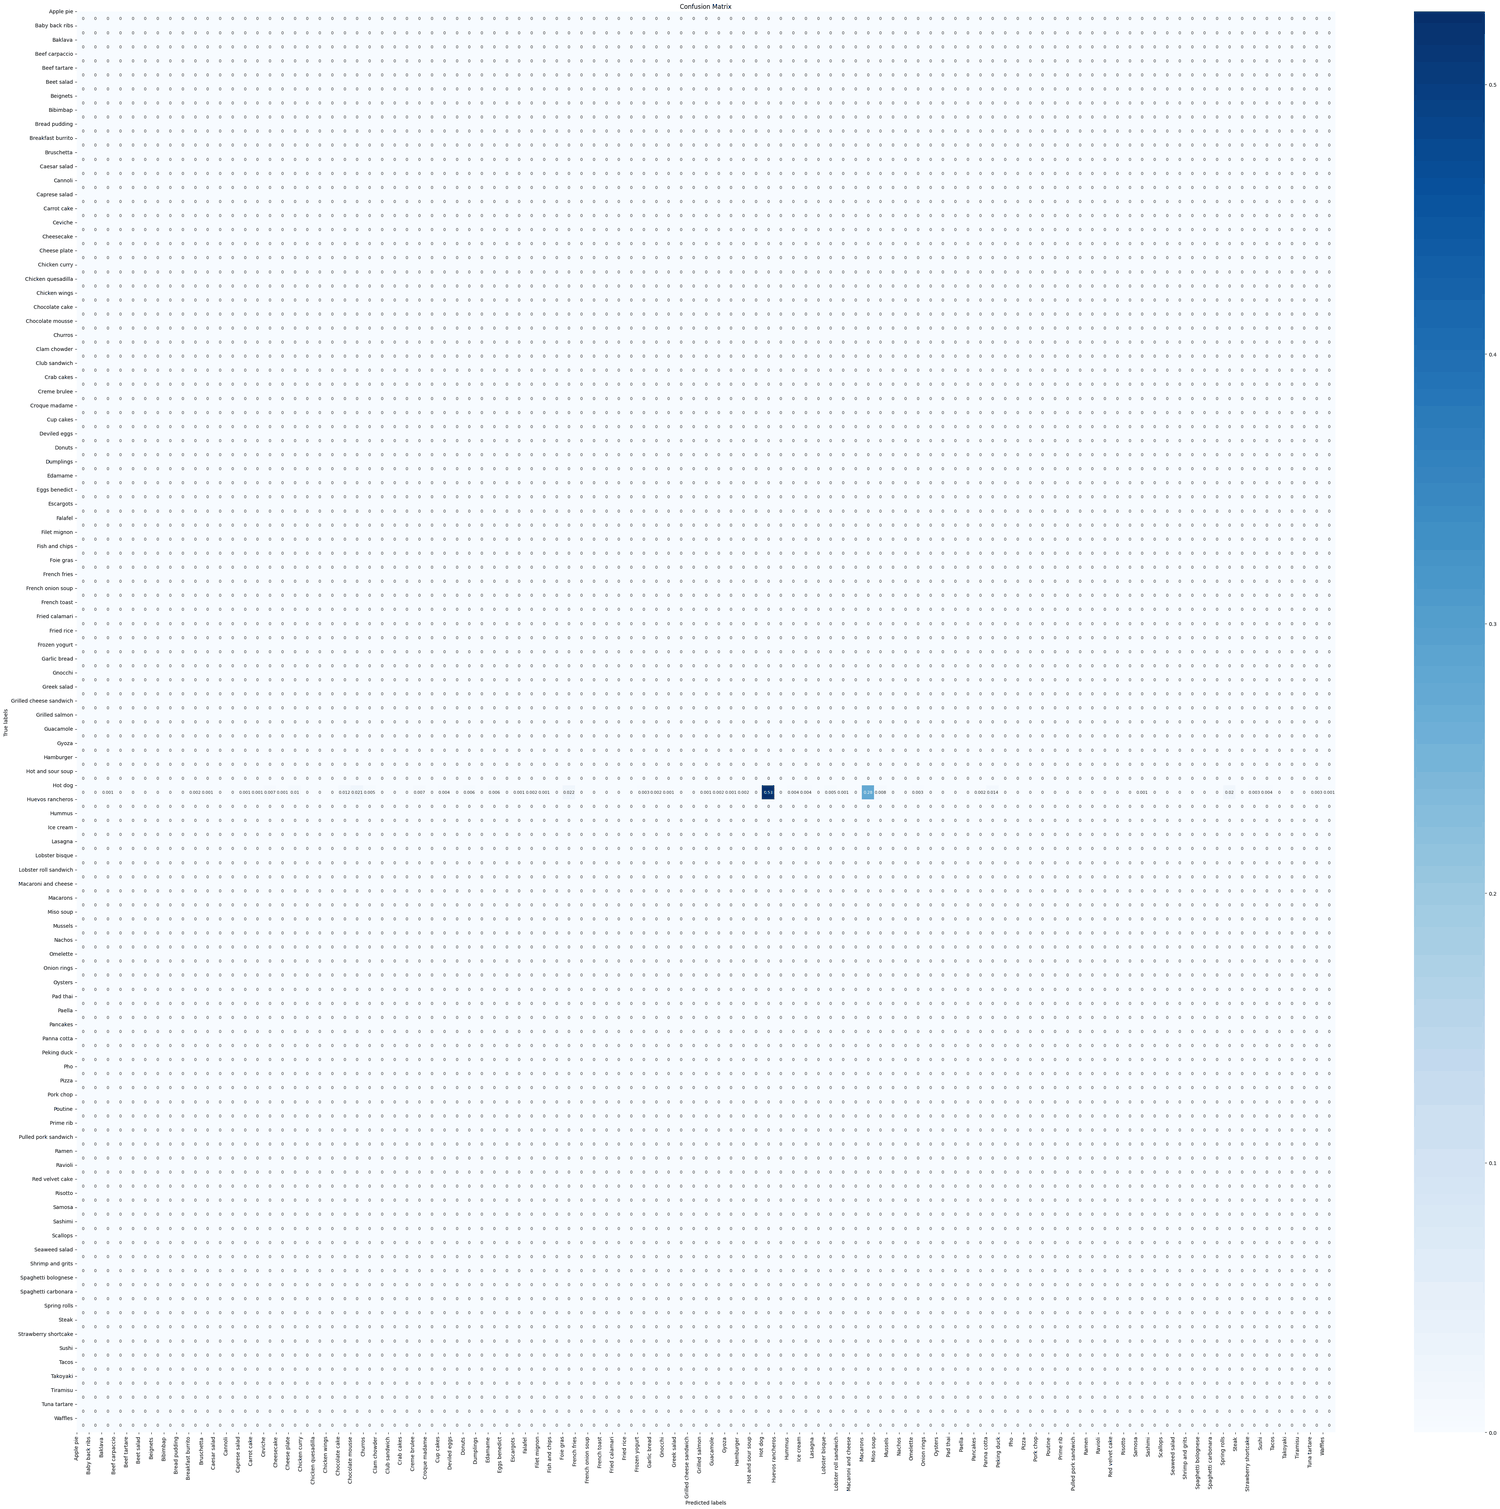

Predicted label ['Macarons' 'Macarons' 'Edamame' 'Macarons' 'Macarons' 'Macarons'
 'Chocolate cake' 'Omelette' 'Panna cotta']
True label ['Hot dog' 'Hot dog' 'Hot dog' 'Hot dog' 'Hot dog' 'Hot dog' 'Hot dog'
 'Hot dog' 'Hot dog']
Corresponding images are shown below


0.527

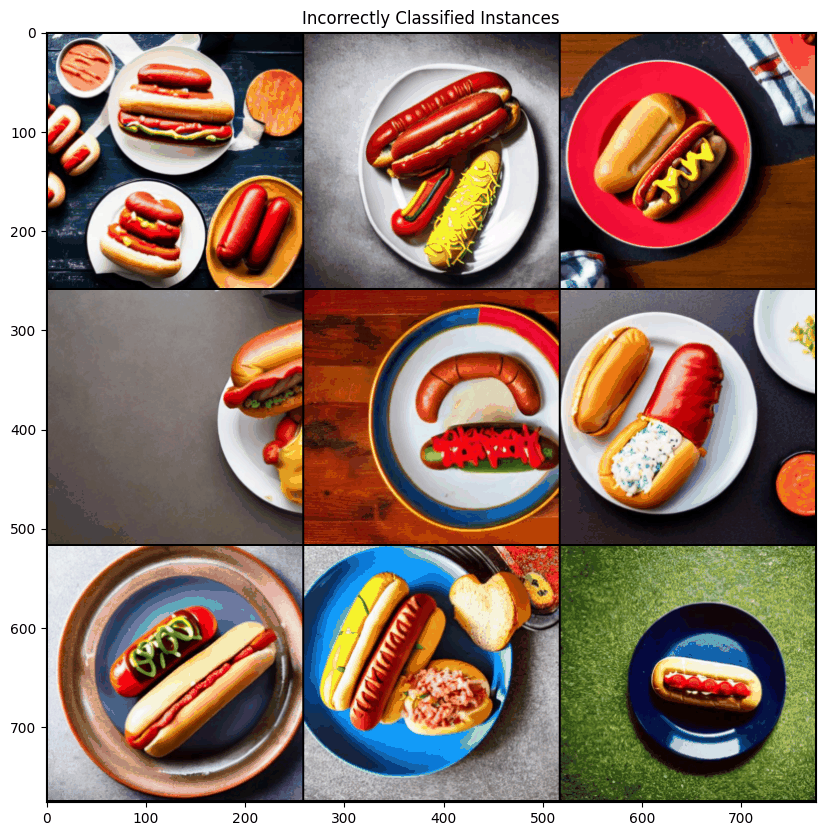

In [ ]:
check_accuracy(synth_hotdog_loader, model_final, analysis=True, hotdog_data=True)

**Answer:**


- The model achieved approximately 52.7% accuracy on the custom hot dog dataset (much lower than its performance on the original validation set).

- This performance drop is mainly due to dataset shift, as the custom dataset contains synthetic and stylised images with different textures, colours, and backgrounds compared to the Food-101 training data.

- Many misclassifications occurred for unusual layouts and artistic styles, which suggests that the model relies on training-specific visual cues rather than fully learning the semantic concept of a hot dog.

- In addition, the model was trained for multi-class food classification, not specifically for robust binary detection.

- Method to improve performance: (1) use stronger and more diverse data augmentation (e.g., heavy colour jitter, texture variation, and style-based augmentation) during training. This would encourage the model to learn more general, domain-invariant features instead of relying on dataset-specific visual patterns, improving robustness to distribution shifts. (2) fine-tuning on the custom dataset.

## Part 3: Feature visualisation

### Q3.1: Learned features

In [ ]:
import matplotlib.pyplot as plt

def plot_model_features():
    fig = plt.tight_layout()
    activation = {}
    def get_activation(name):
        def hook(model, input, output):
            activation[name] = output.detach()
        return hook
    vis_labels = ['conv1', 'layer1', 'layer2', 'layer3', 'layer4']

    for l in vis_labels:
        getattr(model_final, l).register_forward_hook(get_activation(l))
        

    data, _ = test_dataset[999]
    data = data.unsqueeze_(0).to(device = device, dtype = dtype)
    output = model_final(data)

    for idx, l in enumerate(vis_labels):
        act = activation[l].squeeze()

        # only showing the first 16 channels
        ncols, nrows = 8, 2
        
        fig, axarr = plt.subplots(nrows, ncols, figsize=(15,5))
        fig.suptitle(l)

        count = 0
        for i in range(nrows):
            for j in range(ncols):
                axarr[i, j].imshow(act[count].cpu())
                axarr[i, j].axis('off')
                count += 1

<Figure size 640x480 with 0 Axes>

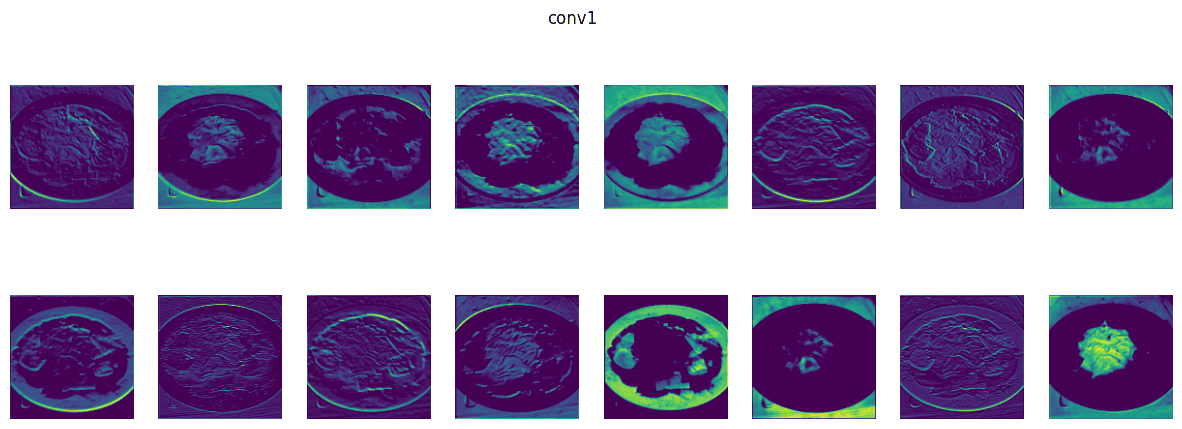

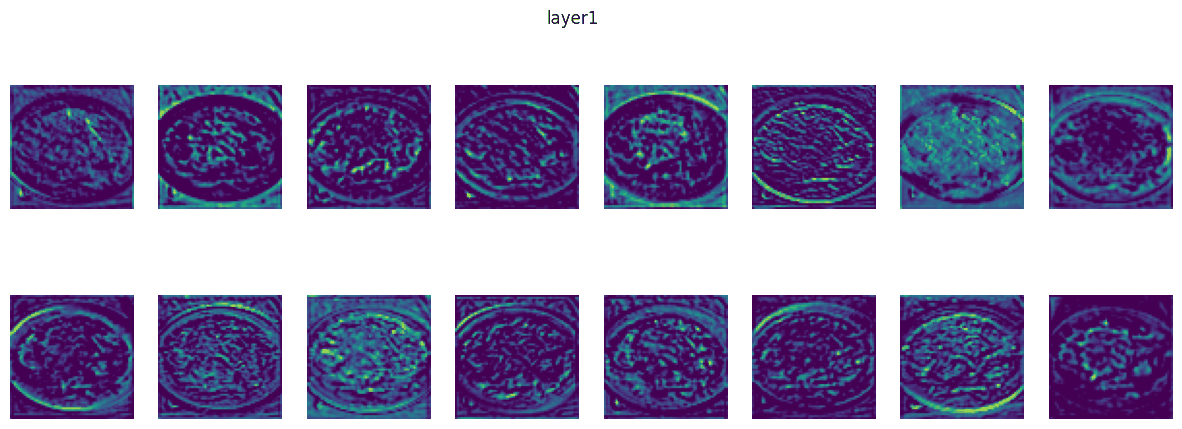

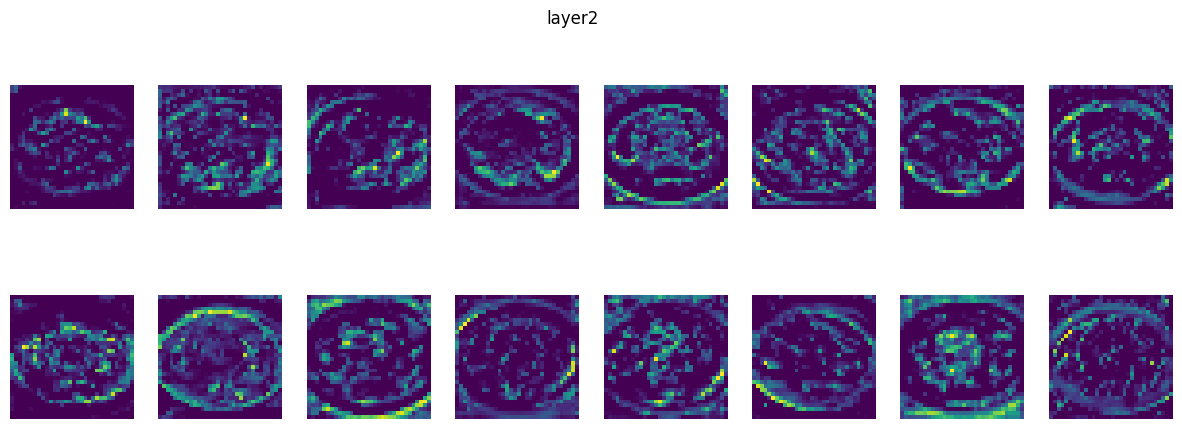

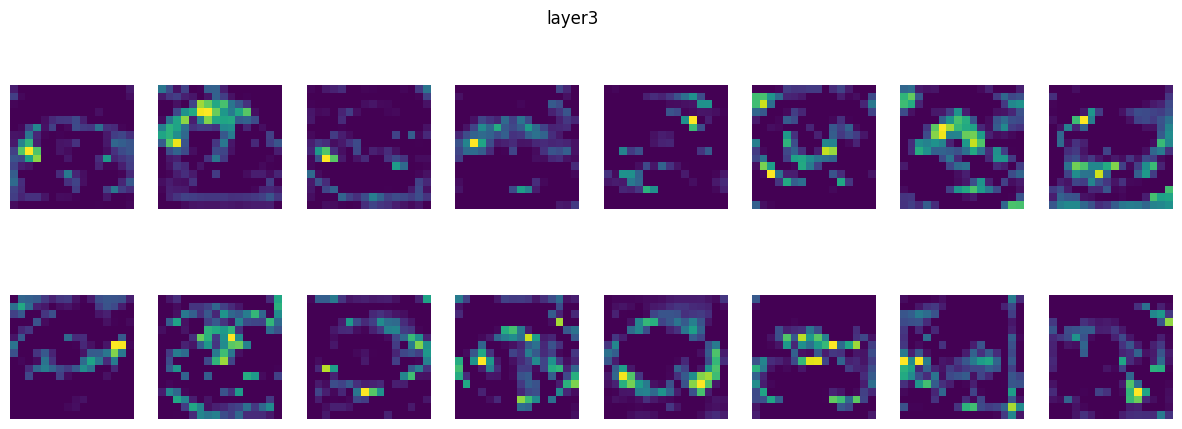

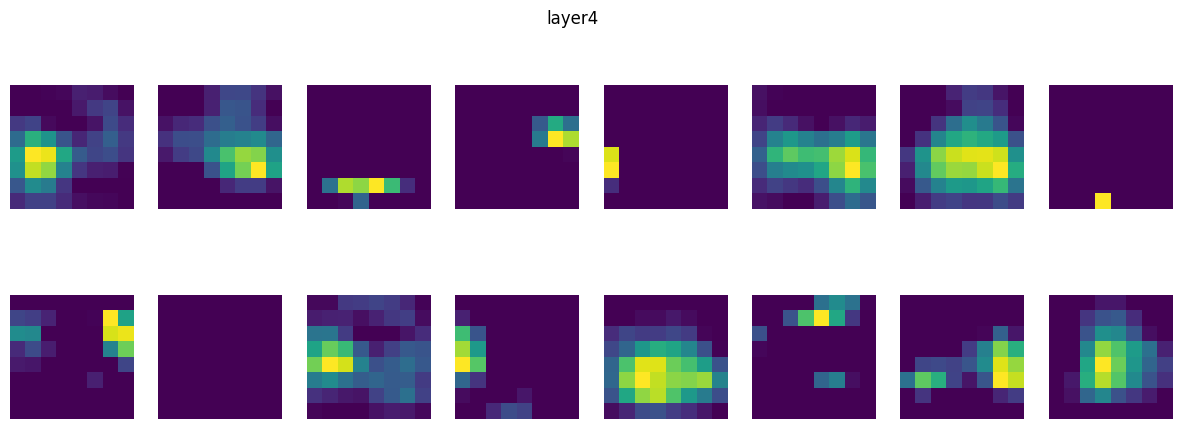

In [ ]:
# Visualize the figure here, so it is exported nicely
plot_model_features()  

**Answer:**

- In the low-level layers (conv1 and layer1), the feature maps mainly capture basic visual patterns such as edges, contours, colour contrasts, and simple textures around the plate and hot dog boundaries.

- These early layers preserve much of the spatial structure of the input image and respond strongly to local intensity changes.

- In the mid-level layers (layer2 and layer3), the feature maps become more abstract and focus on combinations of edges and textures, such as sausage shapes, plate outlines, and internal texture patterns.

- These layers start to suppress background details and emphasise more meaningful object-related regions.

- In the high-level layer (layer4), the feature maps are highly compressed and sparse, activating mainly on discriminative regions of the image, such as the central hot dog area.

- Most background information is removed, and the activations represent high-level semantic features rather than raw visual patterns.

### Q3.2: Performance analysis

**Answer:**

- The improved model achieved 65.33% validation accuracy and 70.96% test accuracy, which is a large improvement over the baseline (13.59%). This suggests that the architecture changes (wider/deeper ResNet-style), stronger data augmentation, and the updated training setup were effective.

- From the [training curves](#viz) in the "My Modifications" section, the training loss decreases smoothly and the validation accuracy increases steadily before plateauing, which suggests stable convergence. I think BatchNorm, AdamW, and cosine learning rate scheduling helped keep training stable and improved generalisation.

- The feature visualisations show the expected hierarchy: early layers respond to edges/textures, while deeper layers activate on more object-level regions, which indicates the model is learning meaningful representations.

- Even so, performance is still moderate for a 101-class task, and the confusion matrix shows that the model often confuses visually similar food categories, which is consistent with a fine-grained classification problem.

- Some deeper-layer feature maps are quite sparse, which may indicate that the model is only strongly activating on a few patterns and not consistently capturing all discriminative cues.

- To improve performance, I would use a deeper or pretrained model (e.g., ImageNet pretrained ResNet) and/or stronger augmentation, which should increase feature quality and help separate similar classes.